# P3｜房價預測：模型與 Training-only Cross Validation

本 Notebook 使用 P1 固定切分，比較三層 baseline 與 OLS、Ridge、Lasso、Elastic Net。
每個模型比較 SalePrice 與 log1p(SalePrice)，預測還原為美元後計算 MAE、RMSE、R²。

**本 Notebook 的角色是 training-only model screening。** 它不單獨選定 Final Model，也不讀取 Final Test；後續 05、06、04 已依序完成 feature ablation、model choice 與一次性 Final Test。
本階段使用 Raw 特徵建立基準；P2 的 Top-k、Engineered 與交互作用已在 05 中完成比較。

## 操作順序
1. 確认下方設定，再從第一格依序執行。
2. 檢查資料切分與前處理驗收。
3. 執行調參與 CV 比較；檢查收斂警告、搜尋邊界及異常分数。
4. 將本階段結果交給 05 做特徵比較，再由 06 固定 Model Choice，最後由 04 做一次性 Final Test。

套件需求：numpy、pandas、scipy、scikit-learn、Jupyter。未經同意不安裝套件。

In [1]:
from pathlib import Path
import json, hashlib, platform, time, warnings, inspect
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.special import boxcox1p
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/outputs/p1/data_split.csv').exists()), None)
assert ROOT is not None, '請從專案資料夾或 notebooks/ 執行。'
MODEL_ROOT = ROOT / 'model'
OUTPUT = MODEL_ROOT / 'results/tables/model_evaluation'
SEED = 42
# 以下設定經使用者確認；執行不會使用 Final Test。
REMOVE_P1_OUTLIERS = True
SEARCH_APPROVED = True
ENVIRONMENT_APPROVED = True
RUN_EXPERIMENTS = True
N_JOBS = 1
print('Project:', ROOT)
print('Python:', platform.python_version(), 'sklearn:', sklearn.__version__)


Project: /data/chingyufan/Data_mining/HW1/Data-Mining-HW1
Python: 3.11.8 sklearn: 1.4.1.post1


## 1. 資料與固定切分

僅依 data_split.csv 中 training 的 Id 讀取原始住宅資料。原始檔雖包含封存資料，程式在讀取時即篩除 test 列；不載入 test 的 target 或特徵。
不使用 P1 已完成補值的 readable/encoded CSV，避免各 validation fold 資訊混入前處理。
沿用 P1 刪除 Id 524、1299。其餘 CV 編號不變。
排除 Id、SalePrice 與成交資訊，並沿用 P1 刪除 Utilities、GarageYrBlt。

In [2]:
import csv
split_path = ROOT / 'data/outputs/p1/data_split.csv'
raw_path = ROOT / 'data/raw_data_FromKaggle/train.csv'
splits = pd.read_csv(split_path)
assert splits['Id'].is_unique
assert set(splits['split']) == {'train', 'test'}
training_ids = set(splits.loc[splits['split'].eq('train'), 'Id'])
with raw_path.open(encoding='utf-8-sig', newline='') as f:
    rows = [row for row in csv.DictReader(f) if int(row['Id']) in training_ids]
train = pd.DataFrame(rows).replace({'': np.nan, 'NA': np.nan, 'None': np.nan})
assert len(train) == len(training_ids)
for col in train:
    if col not in ['Id']:
        try:
            train[col] = pd.to_numeric(train[col])
        except (ValueError, TypeError):
            pass
train['Id'] = pd.to_numeric(train['Id']).astype(int)
train = train.merge(splits.loc[splits['split'].eq('train'), ['Id', 'cv_fold']],
                    on='Id', validate='one_to_one').sort_values('Id').reset_index(drop=True)
assert train['cv_fold'].notna().all()
assert REMOVE_P1_OUTLIERS is not None, '請先確認是否沿用 P1 異常值刪除。'
if REMOVE_P1_OUTLIERS:
    assert set(train.loc[(train.GrLivArea > 4000) & (train.SalePrice < 300000), 'Id']) == {524, 1299}
    train = train.loc[~train.Id.isin([524, 1299])].reset_index(drop=True)
EXCLUDED = ['Id', 'SalePrice', 'cv_fold', 'YrSold', 'MoSold', 'SaleType', 'SaleCondition',
            'Utilities', 'GarageYrBlt']
X = train.drop(columns=EXCLUDED)
y = train['SalePrice'].astype(float)
fold_ids = train['cv_fold'].astype(int).to_numpy()
cv = list(PredefinedSplit(fold_ids).split())
assert set(fold_ids) == set(range(5))
assert y.gt(0).all()
assert not set(train.Id) & set(splits.loc[splits['split'].eq('test'), 'Id'])
display(train.groupby('cv_fold').size().rename('validation_rows').to_frame())
print('Training:', X.shape, '| Final Test 未載入')


Training: (1166, 73) | Final Test 未載入


,validation_rows
cv_fold,
0.0,233
1.0,234
2.0,234
3.0,232
4.0,233


## 2. P1 前處理改成 fold 內 fit

沿用 P1：沒有設施補 None／0、有地下室但品質未知補 training fold 眾數、臨街長度補同社區中位數再以整體中位數兜底；其餘缺值依 P1 規則補。
有序映射直接從 P1 靜態定義取得，不重新決定順序；住宅類型代碼視為名目類別。
名目欄位 one-hot，只在 fit 時學習類別，未知類別使用全零。
數值欄在該 fold 的 training 偏態絕對值 > 0.75 時，使用 boxcox1p(λ=0.15)，再 RobustScaler；one-hot 不縮放。

注意：RobustScaler 不會移除極端房屋或保證模型對極端值穩健。OLS 不要求輸入或 target 本身為常態；log 目標的效果由 CV 比較。
單特徵 OLS 保留原始 GrLivArea 的線性關係，僅補值、縮放，不做 Box-Cox。

In [3]:
ORDINAL = {'Street': {'Grvl': 0, 'Pave': 1, 'None': 0}, 'Alley': {'Grvl': 1, 'Pave': 2, 'None': 0}, 'LotShape': {'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0, 'None': 0}, 'LandSlope': {'Gtl': 2, 'Mod': 1, 'Sev': 0, 'None': 0}, 'ExterQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'ExterCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0}, 'BsmtFinType1': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}, 'BsmtFinType2': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}, 'HeatingQC': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'CentralAir': {'Y': 1, 'N': 0, 'None': 0}, 'KitchenQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'Functional': {'Typ': 7, 'Min1': 6, 'Min2': 5, 'Mod': 4, 'Maj1': 3, 'Maj2': 2, 'Sev': 1, 'Sal': 0, 'None': 0}, 'FireplaceQu': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0}, 'GarageQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'GarageCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'PavedDrive': {'Y': 2, 'P': 1, 'N': 0, 'None': 0}, 'PoolQC': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'Fence': {'GdPrv': 4, 'MnPrv': 3, 'GdWo': 2, 'MnWw': 1, 'None': 0}}


In [4]:
class P1FoldPreparation(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.frontage_by_neighborhood_ = X.groupby('Neighborhood')['LotFrontage'].median()
        self.frontage_global_ = X['LotFrontage'].median()
        self.modes_ = {}
        for col in X.select_dtypes(include='object'):
            mode = X[col].mode()
            self.modes_[col] = mode.iloc[0] if len(mode) else 'None'
        return self

    def transform(self, X):
        out = X.copy()
        for col in ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu',
                    'GarageType','GarageFinish','GarageQual','GarageCond','MasVnrType']:
            out[col] = out[col].fillna('None')
        for col in ['GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF',
                    'TotalBsmtSF','BsmtFullBath','BsmtHalfBath','MasVnrArea']:
            out[col] = out[col].fillna(0)
        for col in ['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']:
            has_basement = out['TotalBsmtSF'] > 0
            out.loc[out[col].isna() & has_basement, col] = self.modes_[col]
            out[col] = out[col].fillna('None')
        out['LotFrontage'] = out['LotFrontage'].fillna(
            out.Neighborhood.map(self.frontage_by_neighborhood_)).fillna(self.frontage_global_)
        for col in ['MSZoning','Electrical','KitchenQual','Exterior1st','Exterior2nd']:
            out[col] = out[col].fillna(self.modes_[col])
        out['Functional'] = out['Functional'].fillna('Typ')
        for col, mapping in ORDINAL.items():
            values = out[col].map(mapping)
            if values.isna().any():
                raise ValueError(f'{col}: 未定義有序類別 {out.loc[values.isna(), col].unique()}')
            out[col] = values.astype(float)
        out['MSSubClass'] = out['MSSubClass'].astype(str)
        return out

class FoldBoxCox(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        s = np.array([skew(a[:, j]) if np.ptp(a[:, j]) > 0 else 0
                      for j in range(a.shape[1])])
        self.selected_ = np.flatnonzero(np.abs(s) > .75)
        return self

    def transform(self, X):
        a = np.asarray(X, dtype=float).copy()
        if a.shape[1] != self.n_features_in_:
            raise ValueError('數值欄位數不同')
        if self.selected_.size:
            if np.any(a[:, self.selected_] < 0):
                raise ValueError('P1 Box-Cox 欄位出現負值，需確認處理規則')
            a[:, self.selected_] = boxcox1p(a[:, self.selected_], .15)
        return a

onehot_kwargs = {'handle_unknown': 'ignore'}
onehot_kwargs['sparse_output' if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else 'sparse'] = False

def make_pipeline(model, single=False, trivial=False):
    if single:
        return Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale', RobustScaler()), ('model', model)])
    if trivial:
        return Pipeline([('impute', SimpleImputer(strategy='median')), ('model', model)])
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('boxcox', FoldBoxCox()), ('scale', RobustScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(**onehot_kwargs))])
    columns = ColumnTransformer([
        ('numeric', numeric, make_column_selector(dtype_include=np.number)),
        ('categorical', categorical, make_column_selector(dtype_include=object))])
    return Pipeline([('p1', P1FoldPreparation()), ('columns', columns), ('model', model)])


## 3. 搜尋設定（已確認）

Ridge α：10⁻³～10⁴，15 點；Lasso／Elastic Net 美元 α：10⁻¹～10⁴、log α：10⁻⁵～10⁰，各 11 點；l1_ratio：0.1、0.5、0.9。Random Forest 300 棵樹，depth None／10、leaf 1／3、max_features 1.0／0.7。
Training mean 只比較美元目標：對 log 價格取平均再還原是另一個 baseline，不是老師要求的平均成交價。
其餘模型比較 raw／log1p 目標；TransformedTargetRegressor 在 predict 時還原，因此 CV scorer 始終評估 USD。

在相同五折上選參數並報告分數，稱為調參 CV 結果，可能因搜尋而偏樂觀，不是 nested CV 的無偏泛化估計。
Final Test 完全封存，當前結果不代表最終測試結果。


### OLS 數值求解（使用者已確認）
完整 one-hot 與面積組成欄位使矩陣不滿秩。OLS 使用中心化後的 SVD 最小平方求解，容差 rcond=max(n,p)×machine epsilon；低於相對容差的奇異值視為零，不加懲罰。保留所有 P1 特徵，但非唯一係數不可當作獨立效應解釋。每折 rank 與容差另存於 fold scores。


In [5]:
class StableOLS(BaseEstimator):
    def fit(self, X, y):
        a = np.asarray(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        self.x_mean_ = a.mean(axis=0)
        self.y_mean_ = float(np.mean(y))
        centered = a - self.x_mean_
        self.rcond_ = max(centered.shape) * np.finfo(float).eps
        self.coef_, _, self.rank_, self.singular_ = np.linalg.lstsq(
            centered, np.asarray(y) - self.y_mean_, rcond=self.rcond_)
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

def candidates():
    assert SEARCH_APPROVED
    for name, model, feature_kind in [
        ('Mean', DummyRegressor(strategy='mean'), 'trivial'),
        ('SingleOLS', LinearRegression(), 'single'),
        ('OLS', StableOLS(), 'raw'),
        ('Ridge', Ridge(), 'raw'),
        ('Lasso', Lasso(max_iter=100000), 'raw'),
        ('ElasticNet', ElasticNet(max_iter=100000), 'raw'),
        ('RandomForest', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), 'raw')]:
        for target in (['raw'] if name == 'Mean' else ['raw', 'log1p']):
            base = make_pipeline(clone(model), single=feature_kind=='single', trivial=feature_kind=='trivial')
            estimator = (TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)
                         if target == 'log1p' else base)
            prefix = 'regressor__model__' if target == 'log1p' else 'model__'
            grid = {}
            if name == 'Ridge':
                grid = {prefix+'alpha': np.logspace(-3, 4, 15)}
            elif name in ['Lasso', 'ElasticNet']:
                grid = {prefix+'alpha': np.logspace(-1, 4, 11) if target == 'raw' else np.logspace(-5, 0, 11)}
                if name == 'ElasticNet':
                    grid[prefix+'l1_ratio'] = [.1, .5, .9]
            elif name == 'RandomForest':
                grid = {prefix+'max_depth': [None, 10], prefix+'min_samples_leaf': [1, 3],
                        prefix+'max_features': [1.0, .7]}
            yield name, target, estimator, grid, feature_kind

SCORING = {'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


## 4. 執行 CV、保留每折分數及 OOF 預測

比較結果不會自動指定 Final Model。收斂或未知類別等警告會存入 warnings.csv，不隱藏。
GridSearchCV 的完整候選結果與搜尋參數會輸出，方便檢查最佳值是否落在邊界。
各模型選定的候選參數再以相同 folds 重跑，輸出每個 training 物件的 out-of-fold 預測；不是 test 預測。


In [6]:
assert ENVIRONMENT_APPROVED, '請先確認執行環境。'
assert RUN_EXPERIMENTS, '請先確認尚未決定的實驗設定。'
OUTPUT.mkdir(parents=True, exist_ok=True)
summary, fold_rows, predictions, searches, warning_rows = [], [], [], [], []
for name, target, estimator, grid, feature_kind in candidates():
    features = X[['GrLivArea']] if feature_kind in ['single', 'trivial'] else X
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        search = GridSearchCV(estimator, grid, scoring=SCORING, refit='MAE', cv=cv,
                              n_jobs=N_JOBS, error_score='raise', return_train_score=False)
        search.fit(features, y)
        best = search.best_index_
        for fold, (tr, va) in enumerate(cv):
            fitted = clone(search.best_estimator_).fit(features.iloc[tr], y.iloc[tr])
            pred = fitted.predict(features.iloc[va])
            assert np.isfinite(pred).all(), '預測出現非有限值'
            fold_rows.append({'model': name, 'target': target, 'fold': fold,
                'MAE_USD': mean_absolute_error(y.iloc[va], pred),
                'RMSE_USD': np.sqrt(mean_squared_error(y.iloc[va], pred)),
                'R2': r2_score(y.iloc[va], pred), 'n_validation': len(va)})
            if name == 'OLS':
                pipe = fitted.regressor_ if target == 'log1p' else fitted
                model = pipe.named_steps['model']
                fold_rows[-1].update({'OLS_rank': int(model.rank_),
                    'OLS_features': model.n_features_in_, 'OLS_rcond': model.rcond_})
            predictions.extend({'model': name, 'target': target, 'Id': int(train.Id.iloc[i]),
                'cv_fold': fold, 'actual_USD': float(y.iloc[i]), 'predicted_USD': float(p)}
                for i, p in zip(va, pred))
    warning_rows.extend({'model': name, 'target': target,
        'category': w.category.__name__, 'message': str(w.message)} for w in caught)
    row = {'model': name, 'target': target, 'features': feature_kind,
           'best_params': json.dumps(search.best_params_), 'seconds': time.perf_counter()-start}
    for metric in SCORING:
        sign = 1 if metric == 'R2' else -1
        row[f'CV_{metric}_mean'] = sign*search.cv_results_[f'mean_test_{metric}'][best]
        row[f'CV_{metric}_std'] = search.cv_results_[f'std_test_{metric}'][best]
    summary.append(row)
    table = pd.DataFrame(search.cv_results_)
    table.insert(0, 'target', target); table.insert(0, 'model', name)
    searches.append(table)
    print(name, target, 'MAE USD:', round(row['CV_MAE_mean'], 2))
comparison = pd.DataFrame(summary).sort_values('CV_MAE_mean')
display(comparison)


Mean raw MAE USD: 56391.6
SingleOLS raw MAE USD: 37159.83
SingleOLS log1p MAE USD: 37478.34
OLS raw MAE USD: 19907.14
OLS log1p MAE USD: 14958.18
Ridge raw MAE USD: 18357.71
Ridge log1p MAE USD: 13818.6
Lasso raw MAE USD: 18155.64
Lasso log1p MAE USD: 13745.58
ElasticNet raw MAE USD: 18362.05
ElasticNet log1p MAE USD: 13749.64
RandomForest raw MAE USD: 16554.34
RandomForest log1p MAE USD: 16799.7


,model,target,features,best_params,seconds,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
8,Lasso,log1p,raw,"{""regressor__model__alpha"": 0.0003162277660168...",8.450444,13745.583714,841.379281,21335.693580,3253.478433,0.923523,0.015647
10,ElasticNet,log1p,raw,"{""regressor__model__alpha"": 0.0003162277660168...",80.200612,13749.643116,826.793145,21376.418269,3271.072014,0.923222,0.015808
6,Ridge,log1p,raw,"{""regressor__model__alpha"": 10.0}",7.694832,13818.597085,835.037496,21399.661032,3168.762778,0.923085,0.015102
4,OLS,log1p,raw,{},1.616687,14958.181062,561.441991,24299.155469,3540.325758,0.899573,0.024241
11,RandomForest,raw,raw,"{""model__max_depth"": null, ""model__max_feature...",151.920706,16554.343986,958.099461,26107.292587,2431.402748,0.885198,0.014704
12,RandomForest,log1p,raw,"{""regressor__model__max_depth"": null, ""regress...",142.955532,16799.695889,906.744965,27293.130258,3330.905175,0.875135,0.017883
7,Lasso,raw,raw,"{""model__alpha"": 100.0}",108.954101,18155.640226,1056.431542,27099.480314,3325.606419,0.876369,0.021227
5,Ridge,raw,raw,"{""model__alpha"": 10.0}",7.818879,18357.713136,987.263630,27267.472479,3740.161632,0.874950,0.023508
9,ElasticNet,raw,raw,"{""model__alpha"": 0.09999999999999999, ""model__...",17.659353,18362.047405,983.903235,27263.253030,3728.308943,0.874986,0.023449
3,OLS,raw,raw,{},1.622068,19907.143555,1055.318157,30835.435041,4519.665127,0.836515,0.047502


## 5. 輸出與重現紀錄

資料檔 hash 僅記錄 training 切分與本次實際使用的 training 列，不讀取 Final Test。
將輸出資料夾中的 comparison、fold scores、tuning 與 OOF 預測交給 I2；方法與限制交給 W2。
警告需先檢查，不能忽略收斂問題後直接宣稱某個模型最好。

In [7]:
tables = {
    'cv_model_comparison.csv': comparison,
    'cv_fold_scores.csv': pd.DataFrame(fold_rows),
    'cv_oof_predictions.csv': pd.DataFrame(predictions),
    'tuning_results.csv': pd.concat(searches, ignore_index=True),
    'warnings.csv': pd.DataFrame(warning_rows, columns=['model','target','category','message'])}
for filename, table in tables.items():
    table.to_csv(OUTPUT / filename, index=False, encoding='utf-8-sig')
metadata = {'seed': SEED, 'remove_p1_outliers': REMOVE_P1_OUTLIERS,
    'training_rows': len(train), 'fold_sizes': np.bincount(fold_ids).tolist(),
    'split_sha256': hashlib.sha256(split_path.read_bytes()).hexdigest(),
    'training_sha256': hashlib.sha256(train.to_csv(index=False).encode()).hexdigest(),
    'versions': {'python':platform.python_version(), 'numpy':np.__version__,
                 'pandas':pd.__version__, 'scipy':scipy.__version__, 'sklearn':sklearn.__version__},
    'primary_metric':'MAE_USD', 'final_test_evaluated':False,
    'feature_engineering_available':False,
    'cv_note':'same-fold tuning CV, not nested CV; std uses ddof=0'}
(OUTPUT/'run_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print('Saved:', OUTPUT)


Saved: model/results/tables/model_evaluation


## 6. 本階段之後的完整流程（均已完成）

- 05：完成 Raw／Top-k／Engineered 與 H1–H3；所有選取仍在 fold 內 fit。
- 06：依共線性、矩陣秩、稀疏度、係數穩定性與 CV，固定 Elastic Net + QualityArea + log1p。
- Final Test 前固定 MAE threshold=15,000 USD、alpha=0.0031622776601683794、l1_ratio=0.1。
- 04：使用完整 training 重訓並對 292 筆 Final Test 評估一次；完成差異檢定、係數 CI/p/VIF 與最大誤差案例。
- AI 使用紀錄：Codex 協助編写 Notebook；團隊需檢查實驗設計、執行結果與結論。


# P3 Raw 特徵階段交付

已完成固定 CV、三層 baseline、線性模型與 raw/log 目標調參比較。本節只呈現 Raw-feature training CV；最終模型與 Final Test 結果由 05、06、04 接續完成。

## 結果

| 模型 | 目標 | CV MAE USD ± SD | CV RMSE USD ± SD | CV R² ± SD | 最佳參數 |
|---|---|---:|---:|---:|---|
| Lasso | log1p | 13,745.58 ± 841.38 | 21,335.69 ± 3,253.48 | 0.9235 ± 0.0156 | `{"regressor__model__alpha": 0.00031622776601683794}` |
| ElasticNet | log1p | 13,749.64 ± 826.79 | 21,376.42 ± 3,271.07 | 0.9232 ± 0.0158 | `{"regressor__model__alpha": 0.00031622776601683794, "regressor__model__l1_ratio": 0.9}` |
| Ridge | log1p | 13,818.60 ± 835.04 | 21,399.66 ± 3,168.76 | 0.9231 ± 0.0151 | `{"regressor__model__alpha": 10.0}` |
| OLS | log1p | 14,958.18 ± 561.44 | 24,299.16 ± 3,540.33 | 0.8996 ± 0.0242 | `{}` |
| RandomForest | raw | 16,554.34 ± 958.10 | 26,107.29 ± 2,431.40 | 0.8852 ± 0.0147 | `{"model__max_depth": null, "model__max_features": 0.7, "model__min_samples_leaf": 1}` |
| RandomForest | log1p | 16,799.70 ± 906.74 | 27,293.13 ± 3,330.91 | 0.8751 ± 0.0179 | `{"regressor__model__max_depth": null, "regressor__model__max_features": 0.7, "regressor__model__min_samples_leaf": 3}` |
| Lasso | raw | 18,155.64 ± 1,056.43 | 27,099.48 ± 3,325.61 | 0.8764 ± 0.0212 | `{"model__alpha": 100.0}` |
| Ridge | raw | 18,357.71 ± 987.26 | 27,267.47 ± 3,740.16 | 0.8750 ± 0.0235 | `{"model__alpha": 10.0}` |
| ElasticNet | raw | 18,362.05 ± 983.90 | 27,263.25 ± 3,728.31 | 0.8750 ± 0.0234 | `{"model__alpha": 0.09999999999999999, "model__l1_ratio": 0.9}` |
| OLS | raw | 19,907.14 ± 1,055.32 | 30,835.44 ± 4,519.67 | 0.8365 ± 0.0475 | `{}` |
| SingleOLS | raw | 37,159.83 ± 2,294.91 | 53,091.64 ± 2,645.27 | 0.5210 ± 0.0739 | `{}` |
| SingleOLS | log1p | 37,478.34 ± 2,027.63 | 54,378.85 ± 2,664.37 | 0.4939 ± 0.1009 | `{}` |
| Mean | raw | 56,391.60 ± 1,243.71 | 77,190.34 ± 4,334.06 | -0.0006 ± 0.0007 | `{}` |


SD 是五折標準差，不是信賴區間。所有 MAE／RMSE 單位 USD。

## 簡單分析

目前最低 CV MAE 的線性候選是 **Lasso / log1p**，MAE **13,745.58 ± 841.38 USD**，比平均房價 baseline 降低約 **75.6%**。
最佳 Random Forest target 是 **raw**，MAE **16,554.34 ± 958.10 USD**。線性模型減 Random Forest 的平均差為 **-2,808.76 USD**（負值代表線性較好），5/5 折線性較低。
這些分數來自參數選擇後的相同 folds，不能用於宣稱確認性顯著勝出；本階段不做正式 gap 檢定，後續 04 已在封存 Final Test 完成 paired CI／檢定。

log 模型還原後的美元誤差用來直接比較；目標變換有沒有幫助應依每個模型的 raw/log 對照判斷。較好的 log 分數與價格長尾壓縮相符，但不是因果證明。
Ridge／Lasso／Elastic Net 的正則化可以處理相關特徵與稀有類別；OLS 矩陣不滿秩已透過 SVD 修正，係數仍不可直接解釋成唯一獨立效果。

需要查看 `search_boundary_check.csv` 與 `warning_summary.csv`：最佳 alpha 在邊界不是自動失敗，但後續可在 training 擴範圍；本次完整搜尋與最佳候選重訓均沒有收斂警告，檢查紀錄見 best_candidate_convergence.csv。
OOF 散布與殘差圖只用 training；其高價房屋誤差觀察促成 P2 的品質×面積假設，後續 05 已以 training-only ablation 驗證，沒有用 Final Test 調整。


## 全部實驗設定與理由

- **資料來源**：Kaggle training CSV 中 P1 training Id；1,166 筆。理由：保留全組固定切分；不載入 test 列。
- **異常值**：沿用 P1 移除 Id 524、1299。理由：使用者確認；只作用於 training；不能按 test 誤差刪案例。
- **Validation**：P1 固定 5 folds，seed 42。理由：全方法相同 folds，避免比較受不同切分影響。
- **研究情境**：Ames 同城市同時期的新房屋物件。理由：隨機切分不代表未来年份泛化；缺房產 ID，無法證明相似建案完全獨立。
- **禁止輸入**：Id、target、cv_fold、YrSold、MoSold、SaleType、SaleCondition。理由：識別與成交後資訊不作特徵，避免 leakage。
- **P1 刪欄**：Utilities、GarageYrBlt。理由：沿用 P1：近常數、無車庫時年份補值語義不合理。
- **缺值**：None／0／有地下室品質眾數／同社區臨街中位數。理由：沿用 P1 語義；眾數中位數在各 training fold fit。
- **Encoding**：P1 22 欄靜態順序映射；其餘 one-hot，unknown ignore。理由：保留品質順序；名目類別沒有數字大小；類別只在 fold fit。
- **Box-Cox**：各 training fold |skew| > .75，lambda .15。理由：沿用 P1 壓縮長尾；不以全資料決定欄位，不要求輸入常態。
- **Scaling**：數值 RobustScaler；one-hot 不縮放。理由：沿用 P1 以中位數/IQR 對齊尺度；不等於清除極端值。
- **Single-feature OLS**：GrLivArea；補值/縮放，不做 Box-Cox。理由：測試單一面積資訊；維持原始面積線性 baseline。
- **Mean baseline**：各 fold training SalePrice 平均值。理由：符合 trivial baseline；不以 log 平均冒充美元平均。
- **Strong baseline**：Random Forest，300 trees。理由：非線性參考；同一資訊、前處理與 folds、公平比較。
- **RF search**：depth=None/10；leaf=1/3；max_features=1.0/.7。理由：使用者核准 8 組，測試樹深、葉節點與特徵抽樣。
- **OLS solver**：中心化 SVD，rcond=max(n,p)*float epsilon。理由：完整 one-hot 與面積組成使矩陣不滿秩；使用者核准數值容差，無正則化。
- **Ridge search**：alpha 10^-3～10^4，15 log-spaced values。理由：測試多尺度 L2 懲罰，處理共線性；使用者核准。
- **Lasso/ElasticNet search**：USD alpha 10^-1～10^4；log alpha 10^-5～10^0，各11點。理由：目標尺度不同，alpha 尺度也不同；使用者核准。
- **ElasticNet l1_ratio**：.1/.5/.9。理由：比較以 L2 為主、平衡、以 L1 為主；使用者核准。
- **Target**：raw USD 和 log1p；Mean 只 raw。理由：CV 檢驗右偏價格轉換是否有幫助；expm1 還原後在 USD 評分。
- **Log inverse**：直接 expm1，不做 smearing correction。理由：已同意直接還原方案；不把條件 log 均值還原宣稱無偏美元均值。
- **Metrics**：MAE 主指標；RMSE、R2 補充；mean ± std(ddof=0)。理由：MAE 直觀美元損失；RMSE 關注大錯誤；R2 比例解釋；SD不是CI。
- **Tuning protocol**：同一固定五折 tuning 與 model comparison。理由：這是 tuning CV，非 nested CV；分數可能偏樂觀，Final Test 另行封存。
- **Convergence**：max_iter=100000；保留全部警告。理由：避免不收斂被當成優勝；需查看最佳候選收斂檢查。
- **執行環境**：既有 /opt/anaconda3/bin/python；單 CPU job/thread。理由：使用者同意既有環境，未安裝套件；版本另存 metadata。
- **最終測試**：本 Notebook 不使用；後續 04 已在 freeze 後評估一次。理由：model/hyperparameter/threshold 必須先固定。
- **正式統計**：04 已完成 Final Test paired bootstrap/permutation、係數條件式 bootstrap 與 VIF。

## 本次檔案與交接

- `notebooks/03_model_evaluation.ipynb`：已執行 CV，Markdown 解釋方法，保留 cell outputs。
- `model/notebooks/04_final_evaluation.ipynb`：已完成一次性 Final Test、差異檢定、係數與 VIF、誤差案例。
- `model/results/tables/model_evaluation/cv_model_comparison.csv`：CV 主比較表。
- `tuning_results.csv`：完整超參數候選結果。
- 逐折分數、OOF predictions、搜尋邊界、warnings 與 metadata 均可由本 Notebook 重建；GitHub 精簡版不另外提交。
- `model/results/figures/model_evaluation/cv_mae_comparison.png`：CV MAE mean ± SD。
- `model/results/figures/model_evaluation/raw_stage_oof_residuals.png`：最佳線性候選的探索性 OOF 圖。

I2 負責正式圖表版面；W2 使用本檔方法理由撰寫技術章節；P2 負責特徵與 ablation，P3 提供同一 CV 評估介面。
後續流程已完成：接入 P2 特徵→比較→固定 threshold→freeze→一次 Final Test→正式統計及至少 3 個 error cases。

## 與最終結果的銜接

本階段最低 Raw-feature CV MAE 是 Lasso/log1p 的 13,745.58 USD，但不能只用這個排名決定 Final Model。05 加入 QualityArea 後，06 綜合資料共線性與係數穩定性，最後 freeze 為 Elastic Net + QualityArea + log1p。04 的一次性 Final Test 得到 MAE 14,422.74 USD、RMSE 22,340.04 USD、R² 0.9349，通過事前 15,000 USD MAE 門檻。

## 給 W2 的方法草稿

我們沿用 P1 的固定 train/test 切分與五折 CV，在 training 刪除 P1 定義的兩個異常物件後使用 1,166 筆資料。所有資料學習型前處理（補值、偏態欄位選擇、類別編碼與縮放）僅在各 training fold fit。以美元 MAE 作主要選模指標，同時報 RMSE 與 R² 的五折平均及標準差。比較平均價格、單一面積 OLS、Random Forest，以及 OLS、Ridge、Lasso、Elastic Net。除美元平均 baseline 外，各模型均比較原始與 log1p 價格，log 預測以 expm1 還原後評分。所有超參數僅由 training CV 選擇；本階段未使用 Final Test。相同 folds 同時用於調參與報告，因此這是 tuning CV 的初步估計，不是 nested CV；最終泛化評估在模型與特徵固定後完成。

## AI 使用與貢獻紀錄草稿

P3：實作固定 CV、fold 內前處理、三層 baseline、四種線性模型、raw/log 調參比較、輸出結果及準備最終統計分析流程。
AI：Codex 協助撰寫 Notebook、檢查 leakage/数值問題、執行程式與整理表格；設定經使用者確認或授權採建議，團隊須核對結果、特徵與結論。

## 模型選擇理由與後續正式決策

- OLS：無正則化參考，檢查所有房屋資訊的基本線性預測力；共線性使普通數值求解不穩定，採明確容差的 SVD。
- Ridge：L2 懲罰保留相關特徵並縮小係數，適合面積、品質、房間與設施存在共線性的資料。
- Lasso：L1 懲罰可把弱特徵係數縮成零；目前最低 MAE，可作主要候選，但相關特徵的選擇與係數不一定穩定。
- Elastic Net：結合 L1/L2，兼顧稀疏與相關特徵；目前 log 版本與 Lasso 分數相近。
- 05 接入 P2 特徵後保留 Lasso、Ridge、Elastic Net 比較；06 最終依資料結構與穩定性選擇 Elastic Net，沒有直接採用此階段 MAE 第一名。
- Ridge log 與 Lasso log 的平均 MAE 只差 73.01 USD（約 0.53%）；這不足以單獨證明優劣，係數穩定性與特徵整合後表現也要考慮。
- 原始價格 Elastic Net 的最佳 alpha 落在下界。這是探索限制；其分數不是當前领先候選，所以本版不再擴大已确认的範圍。特徵更新後可重新訂搜尋範圍。

## 重現與驗證

在 Jupyter／VS Code 開啟 03，選擇已有套件的 Anaconda Python 環境（本次 /opt/anaconda3/bin/python），由上而下執行。可從 repo root 或 notebooks/ 起動；程式自動找專案根目錄。
完整 13 組方法 × 5 folds 共 65 組折結果；每個方法均有 1,166 筆 OOF 預測，已逐折重算 MAE、RMSE、R²，與搜尋及結果表一致。Final Test 未載入。
04 已整合 P2 feature pipeline 並執行一次正式 Final Test；292 筆預測與 MAE、RMSE、R² 已重新計算核對，Notebook 無 error output。
本次原始特徵有 73 欄，fold 內 one-hot 類別數可能不同，屬正常現象。不能直接把 P1 全 training 的 213 特徵數套到每折。

## P3 完成狀態

| 項目 | 狀態 | 對應 Notebook |
|---|---|---|
| CV framework、metrics、baselines | 完成 | 03 |
| Raw features 模型與調參 | 完成 | 03 |
| Feature sets、Top-k、Engineered、交互作用、ablation | 完成 | 05 |
| 非 performance-only Model Choice | 完成 | 06 |
| 15,000 USD decision threshold 與 freeze | 完成 | 04 |
| Final Test 與正式主結果 | 完成一次 | 04 |
| Gap CI／p、係數 CI／p／VIF、test error cases | 完成 | 04 |
| 技術說明與正式數字 | 完成 | model/report 與 model/results |


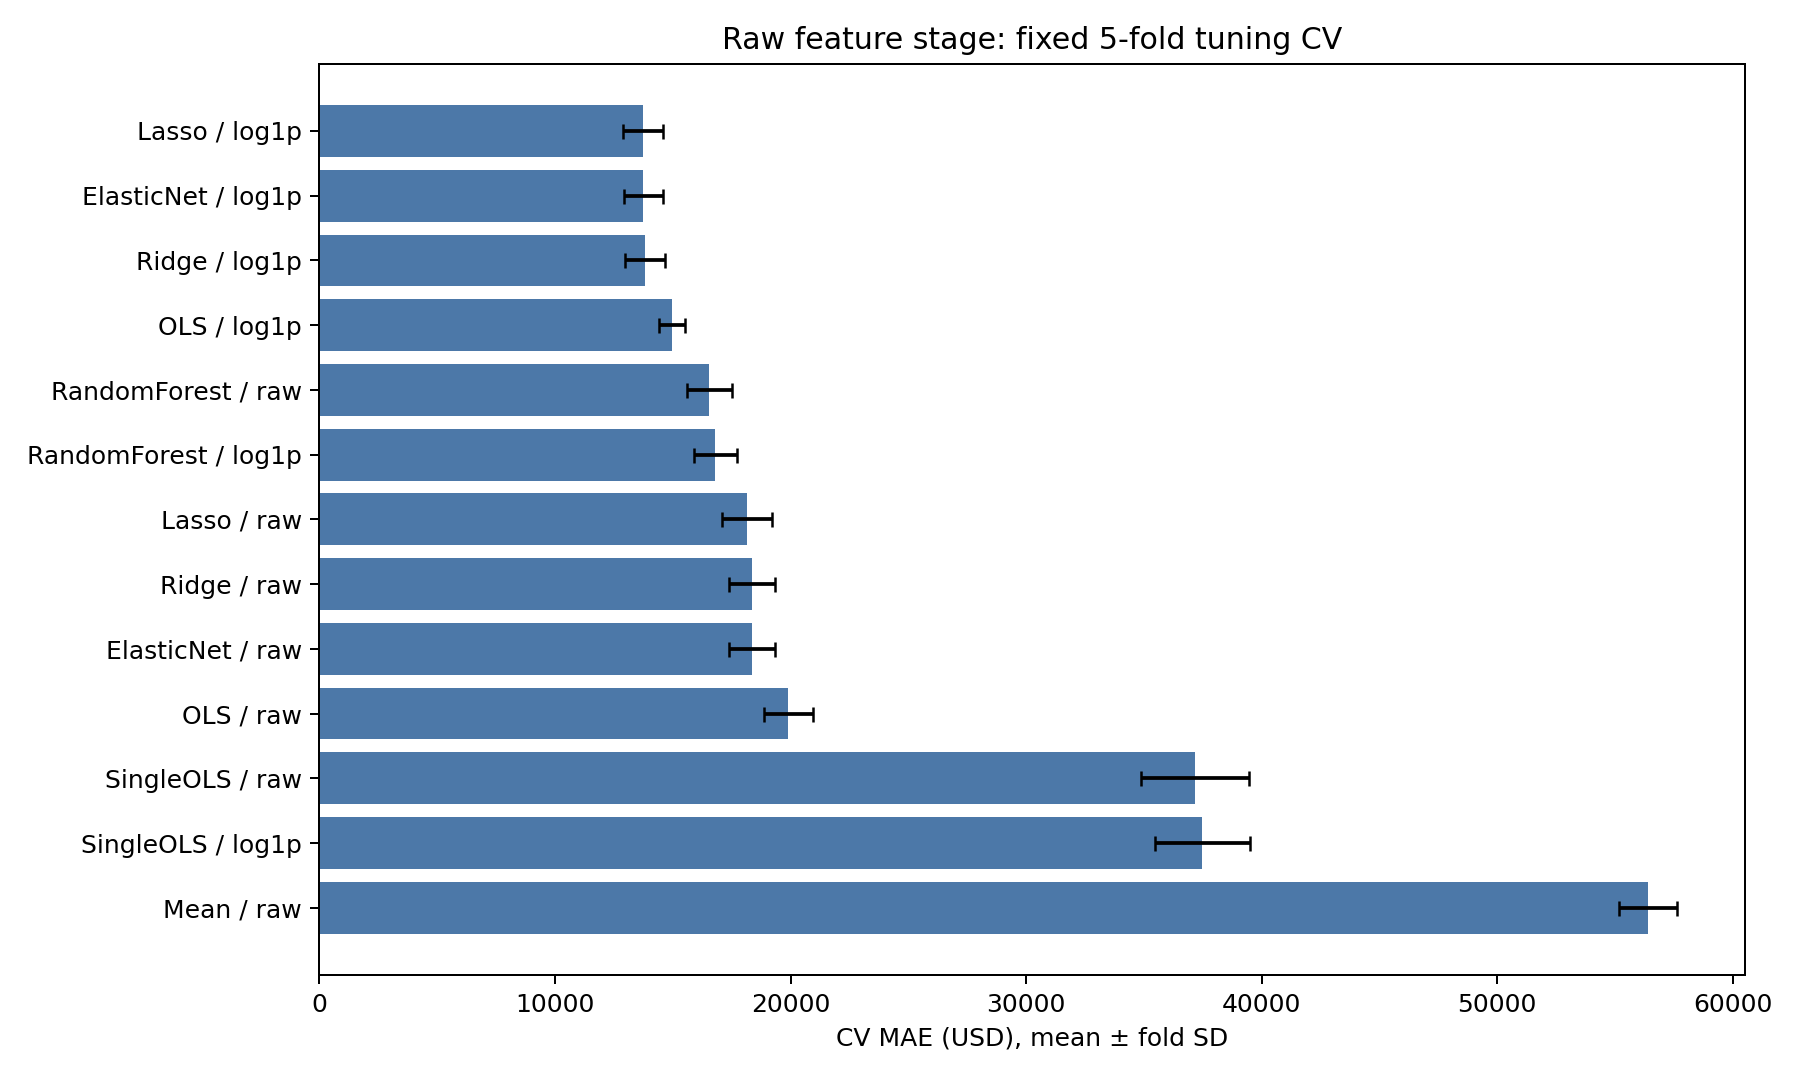

In [8]:
# 重新繪圖僅讀 training CV 的結果，不進行任何 Final Test。
import matplotlib.pyplot as plt
from IPython.display import Image, display
figure_dir = MODEL_ROOT / 'results/figures/model_evaluation'
figure_dir.mkdir(parents=True, exist_ok=True)
results = pd.read_csv(OUTPUT / 'cv_model_comparison.csv').sort_values('CV_MAE_mean')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(np.arange(len(results)), results.CV_MAE_mean,
        xerr=results.CV_MAE_std, color='#4c78a8', capsize=3)
ax.set_yticks(np.arange(len(results)), results.model + ' / ' + results.target)
ax.invert_yaxis()
ax.set(xlabel='CV MAE (USD), mean ± fold SD',
       title='Raw feature stage: fixed 5-fold tuning CV')
fig.tight_layout()
fig.savefig(figure_dir / 'cv_mae_comparison.png', dpi=180)
plt.close(fig)
display(Image(filename=str(figure_dir / 'cv_mae_comparison.png')))
